# Phase Correction

So far, our signal has been modelled as: $$s_n = \sum_{k=1}^{N} d_k z_k^n$$ Where we have defined $\mathcal{z}_k = e^{(-\lambda_k + i 2 \pi f_k) \Delta t}$ and $d_k = A_k e^{i \theta_k}$. We have used our generating function to approach this both as a Pade approximant, and used Matrix Pencil methods alongside SVD to avoid the instability in root finding when we start to introduce noise. We would like to use this method in order to better tackle phase correction. We can see that the phase information $\phi$ is conatined in the $d_k$ coefficients, alongside the amplitude. To a very good approximation, the phase distortion for a specific resonance is $$\phi_k = \phi_0 + \phi_1 (\omega_k - \omega_{ref})$$ We call $\Phi_0$ and $\Phi_1$ the zeroth and first order phase errors, respectively. Hypothetically, we could find phase correction parameters from these recovered resonance co-efficients, rather than requiring the entire Fourier-transformed spectrum. There is real precedent for this. We need to introduce a simple phase error into our generated signals. First, we will establish this technique for a purely 0th order phase error.   

In [1]:
# Imports and Set-up

import pade_utils as pdu
import matplotlib.pyplot as plt
import numpy as np

tmax = 1000
delta_t = 0.01
time = np.linspace(0, tmax * delta_t, tmax)

In [2]:
phi_0 = np.pi / 4

correct_fid = pdu.generate_synthetic_signal(order = 5, noise_level = 0, seed = 18)
phased_fid = correct_fid * np.exp(1j * phi_0)
z_k, d_k = pdu.matrix_pencil(phased_fid, order = 5)
recovered_phi_0 = np.angle(np.sum(np.abs(d_k) * d_k))

print(f"Real Phi0 = {phi_0}")
print(f"Recovered Phi0 = {recovered_phi_0}")

Real Phi0 = 0.7853981633974483
Recovered Phi0 = 0.785398163397442


Great! Let's now add in a simple 1st order (linear) phase error and try to recover this as well. First order phase correction is frequency dependent, the further away something is in the frequency domain from a given reference frequency, the greater the shift we see. We can see that the frequncy information is contained in the $z_k$, and we introduce it here. As we are now recovering both $\phi_0$ and $\phi_1$, we can fi a straight line in order to see the best fit. As this is a simple exampl, all information will lie on a simple line, but when we introduce busy resoannces and noise, we may need more complex techniques.

In [3]:
frequencies = np.angle(z_k) / (2 * np.pi)

phi_0 = np.pi / 4
phi_1 = np.pi / 2

phases = phi_0 + phi_1 * frequencies
d_phased = np.abs(d_k) * np.exp(1j * phases)

n = np.arange(len(correct_fid))
phased_fid = (z_k[None, :] ** n[:, None]) @ d_phased

In [4]:
z_recovered, d_recovered = pdu.matrix_pencil(phased_fid, order=5)

frequencies_recovered = np.angle(z_recovered) / (2 * np.pi)
phases_recovered = np.angle(d_recovered)

idx = np.argsort(frequencies_recovered)

x = frequencies_recovered[idx]
y = np.unwrap(phases_recovered[idx]) # Important so +179 and -179 are only 2 degrees apart, not 358

recovered_phi_1, recovered_phi_0 = np.polyfit(x, y, 1)
recovered_phi_0 = np.angle(np.exp(1j * recovered_phi_0))

print(f"Real Phi0 = {phi_0:.6f}")
print(f"Recovered Phi0 = {recovered_phi_0:.6f}")

print(f"Real Phi1 = {phi_1:.6f}")
print(f"Recovered Phi1 = {recovered_phi_1:.6f}")

Real Phi0 = 0.785398
Recovered Phi0 = 0.785398
Real Phi1 = 1.570796
Recovered Phi1 = 1.570796


This is a useful proof of concept, but we have made several assumptions:
- We have assumed no intrinsic phase $\Theta_k$
- We have only used noiseless signals
- We have only had 5 resonances

Let's wrap this phase estimation in a function and try it out first on busy, noiseless signals.

In [5]:
def retrieve_phases(phased_signal, order, n_datapoints = 200):
    """
    This takes a phased signal, and returns our matrix pencil estimation of the zeroth and first order phase
    """

    z_k, d_k = pdu.matrix_pencil(phased_signal, order = order, n_datapoints = n_datapoints)

    frequencies = np.angle(z_k) / (2 * np.pi)
    phases = np.angle(d_k)

    idx = np.argsort(frequencies)

    x = frequencies[idx]
    y = np.unwrap(phases[idx]) # Important so +179 and -179 are only 2 degrees apart, not 358

    weights = np.abs(d_k)[idx] # Deweight tiny amplitudes (this reduces error by > 99% for K = 30)!
    recovered_phi_1, recovered_phi_0 = np.polyfit(x, y, 1, w=weights)
    recovered_phi_0 = np.angle(np.exp(1j * recovered_phi_0))

    return recovered_phi_0, recovered_phi_1

In [6]:
errors = []

for K in [5, 10, 15, 20, 25, 30]:

    error_k = []

    for seed in range(30):

        rng = np.random.default_rng(seed=seed)
    
        correct_fid, z_k, d_k = pdu.generate_synthetic_signal(order = K, noise_level = 0, seed = seed, return_parameters = True)
        
        frequencies = np.angle(z_k) / (2 * np.pi)
    
        p0, p1 = rng.uniform(0, 2 * np.pi, size=2)
    
        phases = p0 + p1 * frequencies
        d_phased = d_k * np.exp(1j * phases)
    
        n = np.arange(200)
        phased_fid = (z_k[None, :] ** n[:, None]) @ d_phased
    
        p0_est, p1_est = retrieve_phases(phased_fid, order = K)
        
        p0_err = np.abs(np.angle(np.exp(1j * (p0_est - p0))))
        p1_err = np.abs(p1_est - p1)

        error_k.append((p0_err, p1_err))

    errors.append(error_k)  

K_values = [5, 10, 15, 20, 25, 30]

mean_errors = np.mean(errors, axis=1)
std_errors = np.std(errors, axis=1)

print("Mean errors:", np.mean(errors, axis=(0, 1)))
print("Median errors:", np.median(errors, axis=(0, 1)))
print("Maximum errors:", np.max(errors, axis=(0, 1)))

Mean errors: [1.00180797e-06 1.04634789e-05]
Median errors: [4.99371514e-14 2.96984659e-13]
Maximum errors: [0.00012997 0.00143667]


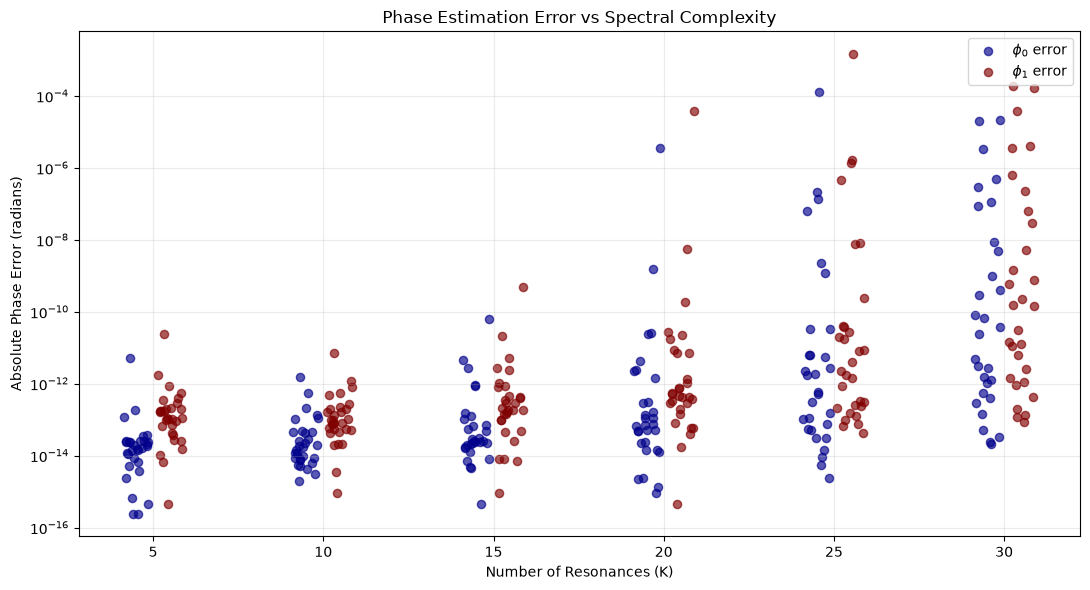

In [7]:
errors = np.asarray(errors)

fig, ax = plt.subplots(figsize=(11, 6))
rng = np.random.default_rng(9823)

for i, K in enumerate(K_values):

    n_seeds = errors.shape[1]
    jitter = rng.uniform(-0.4, 0.4, n_seeds)

    ax.scatter(K + jitter - 0.5, errors[i, :, 0], color="darkblue", alpha=0.65, s=35, label=r"$\phi_0$ error" if i == 0 else None)
    ax.scatter(K + jitter + 0.5, errors[i, :, 1], color="maroon", alpha=0.65, s=35, label=r"$\phi_1$ error" if i == 0 else None)

ax.set_yscale("log")

ax.set_xticks(K_values)
ax.set_xlabel("Number of Resonances (K)")
ax.set_ylabel("Absolute Phase Error (radians)")
ax.set_title("Phase Estimation Error vs Spectral Complexity")

ax.legend()
ax.grid(alpha=0.25, which="both")

plt.tight_layout()
plt.show()

What does this tell us? A few things:
- The more resonances we have, the more error there is in our phase estimation, with all else being equal
- There is an enormous spread on the error. For $K = 20$, the absolute error varies from $10^{-13}$ to $10^{-3}$
- Our average is brought up considerably by a few outliers. This is perhaps less obvious in a logarithmic plot, but for $K=30$, our mean error for $\Phi_1$ is ~ $0.01$ radians, with a few at ~ $0.1$ and one error al ost at unity.


Let's see if increasing the number of datapoints makes a significant impact at high $K$. 

In [8]:
K = 30
N_values = [200, 400, 600, 800, 1000]

errors = []

for n_datapoints in N_values:

    error_n = []

    for seed in range(30):

        rng = np.random.default_rng(seed)

        correct_fid, z_k, d_k = pdu.generate_synthetic_signal(order=K, noise_level=0, seed=seed, return_parameters = True)

        frequencies = np.angle(z_k) / (2 * np.pi)

        p0, p1 = rng.uniform(0, 2 * np.pi, size=2)

        phases = p0 + p1 * frequencies
        d_phased = d_k * np.exp(1j * phases)

        n = np.arange(n_datapoints)
        phased_fid = (z_k[None, :] ** n[:, None]) @ d_phased

        p0_est, p1_est = retrieve_phases(phased_fid, order = K, n_datapoints=n_datapoints)

        p0_err = np.abs(np.angle(np.exp(1j * (p0_est - p0))))
        p1_err = np.abs(p1_est - p1)

        error_n.append((p0_err, p1_err))

    errors.append(error_n)

    print(f"{n_datapoints} finished...")

errors = np.asarray(errors)

200 finished...
400 finished...
600 finished...
800 finished...
1000 finished...


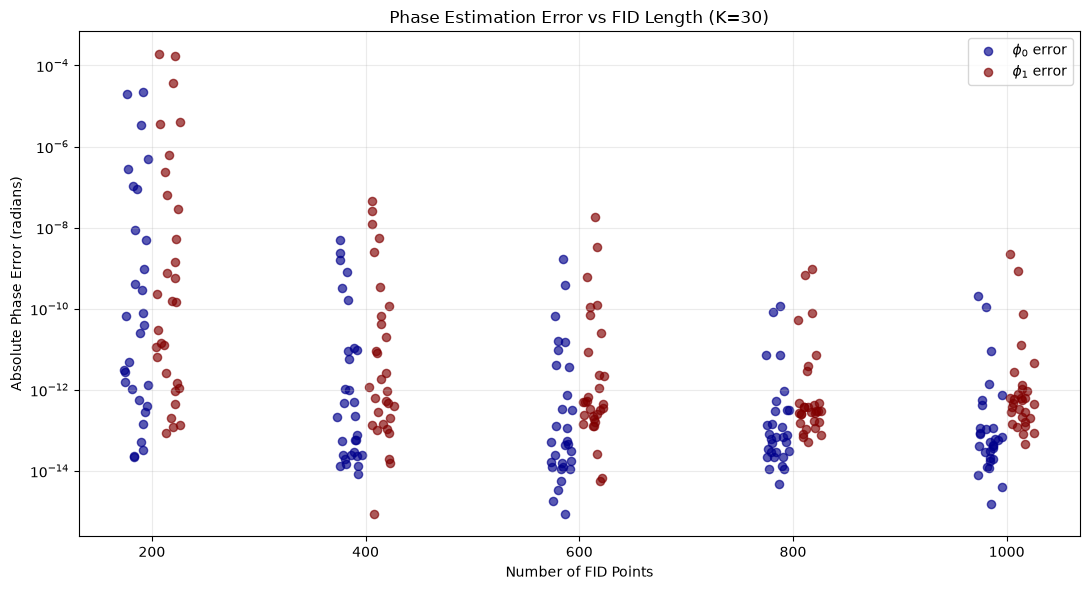

In [9]:
fig, ax = plt.subplots(figsize=(11, 6))
rng = np.random.default_rng(42)

for i, N in enumerate(N_values):

    n_seeds = errors.shape[1]

    jitter = rng.uniform(-12, 12, n_seeds)

    ax.scatter(N + jitter - 15, errors[i, :, 0], color="darkblue", alpha=0.65, s=35,label=r"$\phi_0$ error" if i == 0 else None)
    ax.scatter(N + jitter + 15, errors[i, :, 1], color="maroon", alpha=0.65, s=35, label=r"$\phi_1$ error" if i == 0 else None)

ax.set_yscale("log")

ax.set_xticks(N_values)
ax.set_xlabel("Number of FID Points")
ax.set_ylabel("Absolute Phase Error (radians)")
ax.set_title(f"Phase Estimation Error vs FID Length (K={K})")

ax.legend()
ax.grid(alpha=0.25, which="both")

plt.tight_layout()
plt.show()

This is a huge improvement! Just doubling the datapoints from 200 to 400 drops the avergae error > 5 order of magnitude, and by $600$ it has reached the level of floating point precision. This is an enormous benefit so far, and acts as an effective proof of concept. But what happens when we introduce noise? Can we effectively use SVD truncation? These are the next questions to ask. 

Once this works, then we need to answer:
- How many datapoints do we need? How do we select these cleverly? How does it work with truncated signals?
- How well does this work on real NMR spectra?
- How well does it deal with complications like multiplet structure and baseline distortion?
- How fast is it? Where are the computational bottlenecks?
- In real life we don't know the number of resoannces or the noise level- how can we estimate these well?
- How can we estimate uncertainty in our estimates?
- How does it compare to current MetabolabPy phase correction procedures on real spectra?